# Проект 1. Почему выросла выручка успешных списаний

Вопрос: **выручка успешных списаний выросла из-за числа платящих подписок, из-за среднего чека или из-за того, что реже стали отказывать оплаты?**

Сравниваем **январь и март 2026**. Оба месяца по 31 дню, а 1 марта в прайсе сменилась цена. Февраль между ними короче, поэтому в разложение его не берём: на графике выручки в день видно, что это длина месяца, а не провал.

**Зерно.** Одна строка — одно списание (`payment_id`), участник — подписка, не человек из семейного доступа. Выручка — сумма `amount` только при `status = 'success'`. К `subscription_members` не присоединяемся: иначе одно списание посчитается столько раз, сколько людей сидит на подписке.

Сутки и месяцы — в UTC.


## 1. Подключение

Строка доступа лежит в `.env`, в ноутбуке её нет. Запускать из корня репозитория: `uv run jupyter lab`.


In [1]:
import calendar
import math
import sys

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

try:
    from prime.config import get_engine
except ModuleNotFoundError:
    raise ModuleNotFoundError(
        "Пакет prime не найден: ноутбук запущен не в окружении prime-monitor.\n"
        f"Сейчас Python отсюда: {sys.executable}\n"
        "Закройте JupyterLab, перейдите в корень репозитория и выполните uv run jupyter lab."
    ) from None

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 11
ACCENT = "#1D4E89"
MUTED = "#9CA3AF"
INK = "#111827"


def q(sql: str, **params) -> pd.DataFrame:
    """Запрос в базу. Соединение закрывается сразу, время сессии — UTC."""
    engine = get_engine()
    try:
        with engine.connect() as conn:
            conn.execute(text("set time zone 'UTC'"))
            return pd.read_sql(text(sql), conn, params=params)
    finally:
        engine.dispose()


print("подключились как:", q("select current_user as login").iloc[0, 0])


подключились как: alalnikolaev


## 2. Месячный ряд

Считаем по всем полным месяцам, которые есть в выгрузке. Последний месяц выбрасываем, если в нём нет последнего календарного дня: хвост базы обрывается, и короткий хвост выглядит как падение.

Производные поля:

- средний чек = выручка / число успешных списаний;
- платежей на платящую подписку = успешные списания / число подписок с хотя бы одним успехом;
- доля отказов = `failed` / (`failed` + `success`). Возврат (`refunded`) в знаменатель не входит: это уже прошедшее списание, а не отказ.


In [2]:
last_paid = pd.Timestamp(q("select max(paid_at) as ts from prime.payments").iloc[0, 0])
last_paid = last_paid.tz_convert("UTC")
print("последнее списание:", last_paid.date())

monthly = q(
    """
    select date_trunc('month', paid_at)::date as month_start,
           count(*) filter (where status = 'success') as n_ok,
           count(distinct subscription_id) filter (where status = 'success') as payers,
           sum(amount) filter (where status = 'success') as revenue,
           count(*) filter (where status = 'failed') as n_fail,
           sum(amount) filter (where status = 'refunded') as refunds
    from prime.payments
    group by 1
    order by 1
    """
)
monthly["month_start"] = pd.to_datetime(monthly["month_start"], utc=True)
monthly["month"] = monthly["month_start"].dt.strftime("%Y-%m")
monthly["days"] = monthly["month_start"].map(
    lambda t: calendar.monthrange(t.year, t.month)[1]
)
month_end = last_paid.normalize() + pd.offsets.MonthEnd(0)
if last_paid.normalize() < month_end:
    incomplete = last_paid.strftime("%Y-%m")
    monthly = monthly[monthly["month"] != incomplete].copy()
    print("неполный месяц убран:", incomplete)

for col in ("n_ok", "payers", "revenue", "n_fail", "refunds"):
    monthly[col] = monthly[col].astype(float)

monthly["rev_per_day"] = monthly["revenue"] / monthly["days"]
monthly["price"] = monthly["revenue"] / monthly["n_ok"]
monthly["per_payer"] = monthly["n_ok"] / monthly["payers"]
monthly["fail_rate"] = monthly["n_fail"] / (monthly["n_ok"] + monthly["n_fail"])
monthly["refund_rate"] = monthly["refunds"] / monthly["revenue"]
monthly = monthly.set_index("month")

show = monthly[
    ["days", "revenue", "rev_per_day", "payers", "n_ok", "price", "per_payer", "fail_rate", "refund_rate"]
].copy()
show.columns = [
    "дней", "выручка", "выручка в день", "платящих подписок", "успешных списаний",
    "средний чек", "списаний на подписку", "доля отказов", "возвраты / выручка",
]
show.round(2)


последнее списание: 2026-08-30


неполный месяц убран: 2026-08


,дней,выручка,выручка в день,платящих подписок,успешных списаний,средний чек,списаний на подписку,доля отказов,возвраты / выручка
month,,,,,,,,,
2025-01,31,23141367.0,746495.71,84155.0,84233.0,274.73,1.00,0.03,0.01
2025-02,28,26970400.0,963228.57,98102.0,98200.0,274.65,1.00,0.03,0.01
2025-03,31,31718924.0,1023191.10,111959.0,115476.0,274.68,1.03,0.03,0.01
2025-04,30,32431030.0,1081034.33,117241.0,117970.0,274.91,1.01,0.03,0.01
2025-05,31,35195819.0,1135349.00,124241.0,127981.0,275.01,1.03,0.03,0.01
2025-06,30,35633528.0,1187784.27,128891.0,129672.0,274.80,1.01,0.03,0.01
2025-07,31,38448855.0,1240285.65,135561.0,139745.0,275.14,1.03,0.03,0.01
2025-08,31,39944116.0,1288519.87,141001.0,145284.0,274.94,1.03,0.03,0.01
2025-09,30,40038850.0,1334628.33,144864.0,145750.0,274.71,1.01,0.03,0.01


## 3. Январь → март: из чего сложился прирост

Модель мультипликативная, порядок цепных подстановок — слева направо:

> выручка = платящие подписки × списаний на подписку × средний чек

Сначала меняем число подписок, потом частоту списания, потом цену. Сумма влияний обязана сойтись с фактическим приростом выручки — это проверяет `assert`.


In [3]:
A, B = "2026-01", "2026-03"
assert monthly.loc[A, "days"] == monthly.loc[B, "days"] == 31

factors = ["payers", "per_payer", "price"]
labels = {
    "payers": "платящие подписки",
    "per_payer": "списаний на подписку",
    "price": "средний чек",
}


def contrib(x0: dict, x1: dict, order: list[str]) -> dict:
    """Влияние факторов: каждый по очереди переходит на новое значение."""
    cur, out = dict(x0), {}
    for name in order:
        before = math.prod(cur.values())
        cur[name] = x1[name]
        out[name] = math.prod(cur.values()) - before
    total = math.prod(x1.values()) - math.prod(x0.values())
    assert abs(sum(out.values()) - total) < 0.01, "сумма влияний не равна изменению"
    return out


x0 = monthly.loc[A, factors].to_dict()
x1 = monthly.loc[B, factors].to_dict()
effects = pd.Series(contrib(x0, x1, factors))
delta = monthly.loc[B, "revenue"] - monthly.loc[A, "revenue"]
assert abs(effects.sum() - delta) < 0.01

print(f"{A} → {B}")
print(f"выручка {monthly.loc[A, 'revenue']:,.0f} → {monthly.loc[B, 'revenue']:,.0f} ₽".replace(",", " "))
print(f"прирост {delta:,.0f} ₽".replace(",", " "))
print()
for name in factors:
    print(
        f"{labels[name]:24} {x0[name]:10.2f} → {x1[name]:10.2f}"
        f"    влияние {effects[name]:+12,.0f} ₽".replace(",", " ")
    )
print()
print(f"сумма влияний {effects.sum():,.0f} ₽".replace(",", " "))


2026-01 → 2026-03
выручка 46 905 935 → 58 229 042 ₽
прирост 11 323 107 ₽

платящие подписки         165623.00 →  173875.00    влияние   +2 337 041 ₽
списаний на подписку           1.03 →       1.03    влияние      +24 677 ₽
средний чек                  274.84 →     324.83    влияние   +8 961 388 ₽

сумма влияний 11 323 107 ₽


## 4. Чек вырос из прайса, не из смеси тарифов

Если бы клиенты перетекли с Базового на Расширенный, средний чек тоже вырос бы. Проверяем два источника: справочник цен и фактические суммы успешных списаний.


In [4]:
tariffs = q(
    """
    select tariff_id, tariff_name, monthly_fee, valid_from, valid_to
    from prime.tariffs
    order by tariff_id, valid_from
    """
)
print(tariffs.to_string(index=False))

mix = q(
    """
    select to_char(paid_at, 'YYYY-MM') as month,
           amount,
           count(*) as n
    from prime.payments
    where status = 'success'
      and paid_at >= '2026-01-01'
      and paid_at < '2026-04-01'
      and to_char(paid_at, 'YYYY-MM') in ('2026-01', '2026-03')
    group by 1, 2
    order by 1, 2
    """
)
mix["n"] = mix["n"].astype(int)
mix["share"] = mix["n"] / mix.groupby("month")["n"].transform("sum")
print()
print(mix.to_string(index=False))

jan_amounts = set(mix.loc[mix["month"] == "2026-01", "amount"].astype(float))
mar_amounts = set(mix.loc[mix["month"] == "2026-03", "amount"].astype(float))
assert jan_amounts == {199.0, 399.0}
assert mar_amounts == {249.0, 449.0}

ext = mix[mix["amount"].isin([399.0, 449.0])].set_index("month")["share"]
assert abs(ext["2026-01"] - ext["2026-03"]) < 0.002
print()
print(
    f"доля Расширенного в успешных списаниях: "
    f"{ext['2026-01']:.1%} → {ext['2026-03']:.1%}"
)


 tariff_id tariff_name  monthly_fee valid_from   valid_to
         1     Базовый        199.0 2024-01-01 2026-02-28
         1     Базовый        249.0 2026-03-01 2030-12-31
         2 Расширенный        399.0 2024-01-01 2026-02-28
         2 Расширенный        429.0 2026-02-01 2026-06-30
         2 Расширенный        449.0 2026-03-01 2030-12-31



  month  amount      n    share
2026-01   199.0 105947 0.620789
2026-01   399.0  64718 0.379211
2026-03   249.0 111289 0.620831
2026-03   449.0  67969 0.379169

доля Расширенного в успешных списаниях: 37.9% → 37.9%


## 5. Графики

Каждый график отвечает на один вопрос. Ось столбиков включает ноль.


### 5.1 Выручка в день не падала в феврале

Сырая сумма за февраль меньше январской, потому что в феврале 28 дней. В пересчёте на день ряд до марта растёт плавно, 1 марта делает ступеньку и дальше не откатывается.


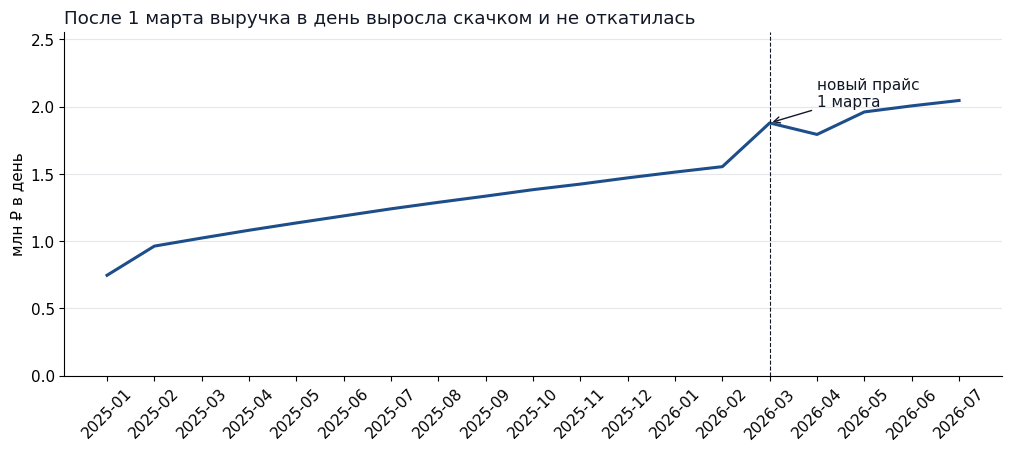

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.4), layout="constrained")
ax.plot(monthly.index, monthly["rev_per_day"] / 1e6, color=ACCENT, linewidth=2.2)
ax.axvline("2026-03", color=INK, linewidth=0.8, linestyle="--")
ax.annotate(
    "новый прайс\n1 марта",
    xy=("2026-03", monthly.loc["2026-03", "rev_per_day"] / 1e6),
    xytext=("2026-04", monthly.loc["2026-03", "rev_per_day"] / 1e6 + 0.12),
    arrowprops={"arrowstyle": "->", "color": INK},
    color=INK,
)
ax.set_title("После 1 марта выручка в день выросла скачком и не откатилась", loc="left", color=INK)
ax.set_ylabel("млн ₽ в день")
ax.set_xlabel("")
ax.set_ylim(0, monthly["rev_per_day"].max() / 1e6 * 1.25)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E5E7EB")
ax.tick_params(axis="x", rotation=45)
plt.show()


### 5.2 Средний чек сдвинулся один раз и застыл

До марта чек стоит на месте около 275 ₽. В марте он переходит на 325 ₽ — это +50 ₽ к обоим тарифам, не постепенный переток в дорогой тариф.


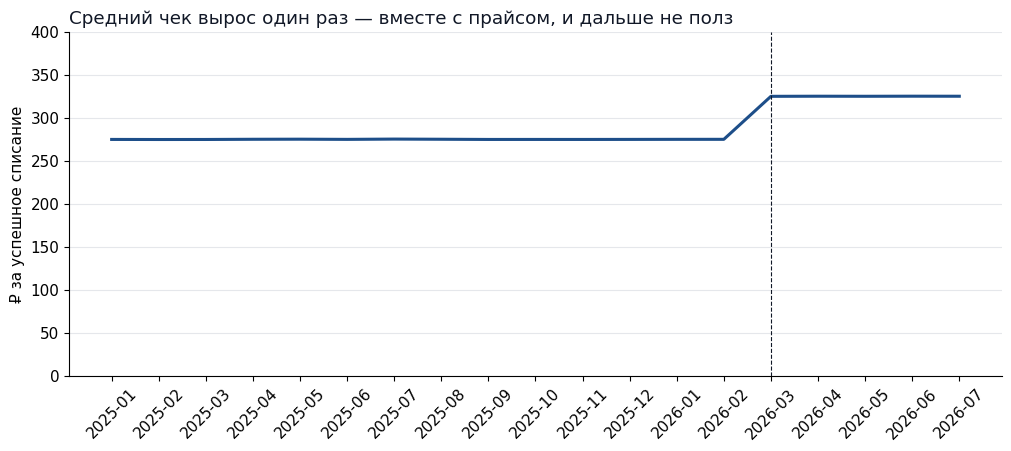

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.4), layout="constrained")
ax.plot(monthly.index, monthly["price"], color=ACCENT, linewidth=2.2)
ax.axvline("2026-03", color=INK, linewidth=0.8, linestyle="--")
ax.set_title("Средний чек вырос один раз — вместе с прайсом, и дальше не полз", loc="left", color=INK)
ax.set_ylabel("₽ за успешное списание")
ax.set_xlabel("")
ax.set_ylim(0, 400)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E5E7EB")
ax.tick_params(axis="x", rotation=45)
plt.show()


### 5.3 Каскад: почти весь прирост — чек

Столбики факторов плывут друг за другом. «Итого» стоит на нуле и равен приросту выручки января к марту. Единицы — тысячи рублей, ноль на оси есть.


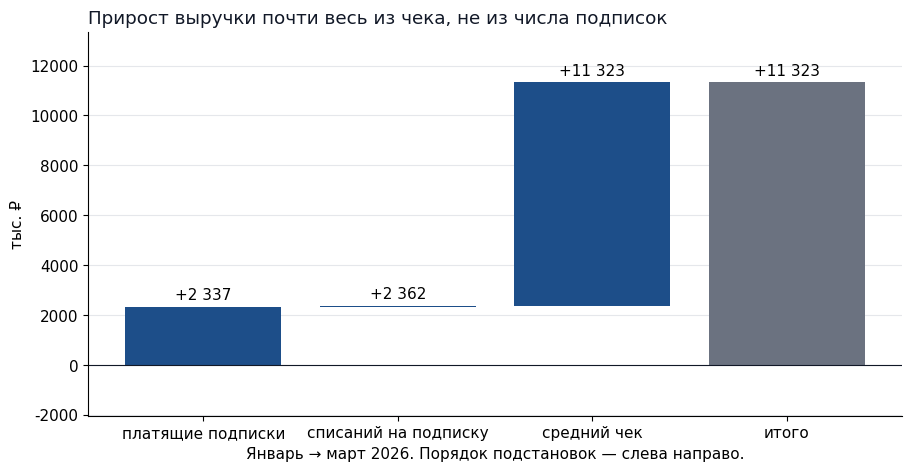

In [7]:
def waterfall(deltas: pd.Series, title: str):
    before = deltas.cumsum() - deltas
    colors = ["#B45309" if value < 0 else "#1D4E89" for value in deltas]
    fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
    bars = ax.bar(deltas.index, deltas, bottom=before, color=colors, zorder=2)
    total = ax.bar("итого", deltas.sum(), color="#6B7280", zorder=2)
    for group in (bars, total):
        ax.bar_label(
            group,
            fmt=lambda v: f"{v:+,.0f}".replace(",", " ").replace("-", "−"),
            padding=3,
        )
    ax.axhline(0, color=INK, linewidth=0.8)
    ax.set_title(title, loc="left", color=INK)
    ax.set_ylabel("тыс. ₽")
    ax.set_xlabel("Январь → март 2026. Порядок подстановок — слева направо.")
    ax.use_sticky_edges = False
    ax.margins(y=0.18)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#E5E7EB")
    return ax


steps = effects.rename(labels) / 1000
waterfall(
    steps,
    title="Прирост выручки почти весь из чека, не из числа подписок",
)
plt.show()


### 5.4 Отказы оплаты ни при чём

Гипотеза была такой: выручка могла вырасти, потому что реже стали падать списания. Доля `failed` среди попыток (успех + отказ) лежит около 3,3% весь ряд. В январе и в марте она совпадает.


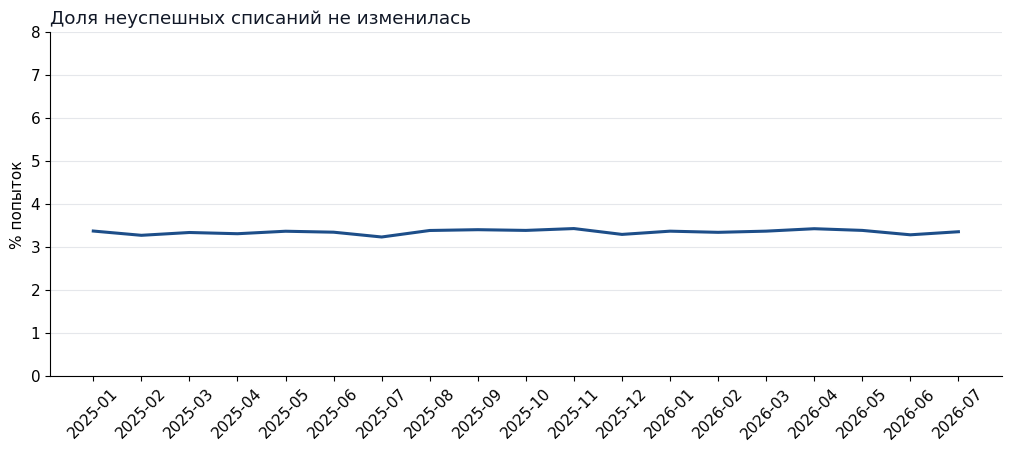

доля отказов 2026-01: 3.36%, 2026-03: 3.36%
возвраты к выручке 2026-01: 1.26%, 2026-03: 1.21%



  month payment_method  fail_rate
2026-01        balance   0.033506
2026-03        balance   0.033093
2026-01           card   0.032792
2026-03           card   0.033033
2026-01            sbp   0.034788
2026-03            sbp   0.034524
2026-01         wallet   0.034304
2026-03         wallet   0.034178


In [8]:
fig, ax = plt.subplots(figsize=(10, 4.4), layout="constrained")
ax.plot(monthly.index, monthly["fail_rate"] * 100, color=ACCENT, linewidth=2.2)
ax.set_title("Доля неуспешных списаний не изменилась", loc="left", color=INK)
ax.set_ylabel("% попыток")
ax.set_xlabel("")
ax.set_ylim(0, 8)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E5E7EB")
ax.tick_params(axis="x", rotation=45)
plt.show()

print(
    f"доля отказов {A}: {monthly.loc[A, 'fail_rate']:.2%}, "
    f"{B}: {monthly.loc[B, 'fail_rate']:.2%}"
)
print(
    f"возвраты к выручке {A}: {monthly.loc[A, 'refund_rate']:.2%}, "
    f"{B}: {monthly.loc[B, 'refund_rate']:.2%}"
)

by_method = q(
    """
    select to_char(paid_at, 'YYYY-MM') as month,
           payment_method,
           count(*) filter (where status = 'failed')::float
             / count(*) filter (where status in ('success', 'failed')) as fail_rate
    from prime.payments
    where paid_at >= '2026-01-01' and paid_at < '2026-04-01'
      and to_char(paid_at, 'YYYY-MM') in ('2026-01', '2026-03')
    group by 1, 2
    order by 2, 1
    """
)
print()
print(by_method.to_string(index=False))


### 5.5 База обоих тарифов после повышения цены росла

Подписка активна в месяце, если началась до его конца и не закончилась до его начала. Канал и члены семьи здесь не нужны: вопрос про то, не съёжилась ли база после нового прайса.


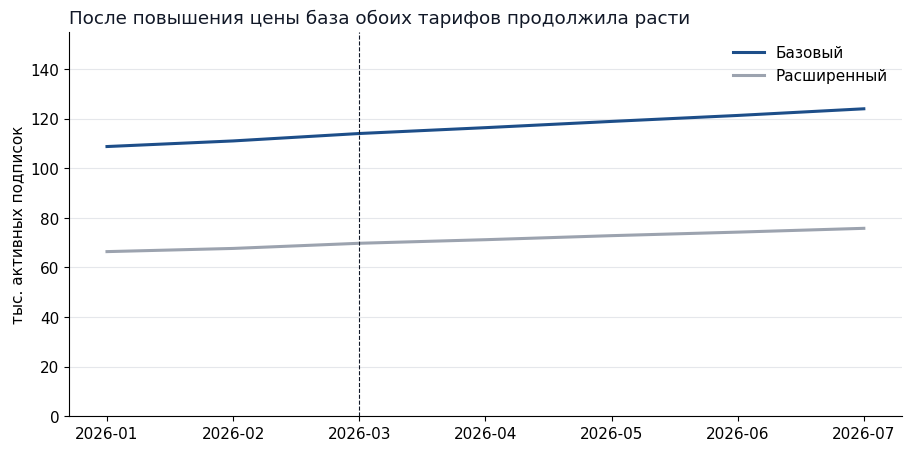

tariff_id  Базовый  Расширенный
month                          
2026-01     108749        66386
2026-02     111012        67670
2026-03     114002        69749
2026-04     116362        71190
2026-05     118879        72821
2026-06     121285        74244
2026-07     123969        75779


In [9]:
active = q(
    """
    select to_char(m.month_start, 'YYYY-MM') as month,
           s.tariff_id,
           count(*) as active
    from generate_series(
             '2026-01-01'::timestamptz,
             '2026-07-01'::timestamptz,
             interval '1 month'
         ) as m(month_start)
    join prime.subscriptions s
      on s.started_at < m.month_start + interval '1 month'
     and (s.ended_at is null or s.ended_at >= m.month_start)
    group by 1, 2
    order by 1, 2
    """
)
active["active"] = active["active"].astype(int)
names = (
    tariffs[["tariff_id", "tariff_name"]]
    .drop_duplicates()
    .set_index("tariff_id")["tariff_name"]
    .to_dict()
)
wide = active.pivot(index="month", columns="tariff_id", values="active")
wide = wide.rename(columns=names)

fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
colors = {col: ACCENT if i == 0 else MUTED for i, col in enumerate(wide.columns)}
for col in wide.columns:
    ax.plot(wide.index, wide[col] / 1000, color=colors[col], linewidth=2.2, label=col)
ax.axvline("2026-03", color=INK, linewidth=0.8, linestyle="--")
ax.set_title("После повышения цены база обоих тарифов продолжила расти", loc="left", color=INK)
ax.set_ylabel("тыс. активных подписок")
ax.set_xlabel("")
ax.set_ylim(0, wide.to_numpy().max() / 1000 * 1.25)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E5E7EB")
plt.show()

print(wide)


## 6. Вывод

Цифры ниже печатает код, они не переписаны руками.


In [10]:
price_effect = effects["price"]
payer_effect = effects["payers"]
freq_effect = effects["per_payer"]
print(
    "Что случилось. Выручка успешных списаний в марте 2026 — "
    f"{monthly.loc[B, 'revenue'] / 1e6:.1f} млн ₽ против "
    f"{monthly.loc[A, 'revenue'] / 1e6:.1f} млн в январе "
    f"(оба месяца по 31 дню): {delta / 1e6:+.1f} млн ₽."
)
print(
    "За счёт чего. "
    f"Средний чек дал {price_effect / 1e6:+.1f} млн ₽, "
    f"число платящих подписок {payer_effect / 1e6:+.1f} млн ₽, "
    f"списаний на подписку {freq_effect / 1e6:+.2f} млн ₽. "
    "Чек вырос, потому что с 1 марта Базовый стоит 249 ₽ вместо 199, "
    "Расширенный — 449 ₽ вместо 399. Доля Расширенного в списаниях не изменилась."
)
print(
    "Чего мы не знаем. Справочник тарифов содержит пересекающуюся цену "
    "Расширенного 429 ₽ на февраль–июнь 2026, но таких сумм в успешных списаниях нет. "
    "Почему строка заведена — по платежам не видно."
)
print(
    "Что делать. Новый прайс оставляем: дневная выручка после марта растёт, "
    "база обоих тарифов растёт, доля отказов осталась около 3,3%. "
    "Разбор «февральского падения» и проект по починке оплат из этих цифр не следуют. "
    "Смотреть выручку в день, а не сумму календарного месяца."
)


Что случилось. Выручка успешных списаний в марте 2026 — 58.2 млн ₽ против 46.9 млн в январе (оба месяца по 31 дню): +11.3 млн ₽.
За счёт чего. Средний чек дал +9.0 млн ₽, число платящих подписок +2.3 млн ₽, списаний на подписку +0.02 млн ₽. Чек вырос, потому что с 1 марта Базовый стоит 249 ₽ вместо 199, Расширенный — 449 ₽ вместо 399. Доля Расширенного в списаниях не изменилась.
Чего мы не знаем. Справочник тарифов содержит пересекающуюся цену Расширенного 429 ₽ на февраль–июнь 2026, но таких сумм в успешных списаниях нет. Почему строка заведена — по платежам не видно.
Что делать. Новый прайс оставляем: дневная выручка после марта растёт, база обоих тарифов растёт, доля отказов осталась около 3,3%. Разбор «февральского падения» и проект по починке оплат из этих цифр не следуют. Смотреть выручку в день, а не сумму календарного месяца.
